# EDA 14 · Relabelled target with a February-only split (70 / 15 / 15)

**Question.** Notebook 13 trained both calendar-cutoff models on February and measured them on March. Here March
is left out completely: the February cohort is split into **train 70 % / tune 15 % / test 15 %**, and the same
two models and the same three training targets are compared on the February `test` part.

| part | share | used for |
|---|---|---|
| train | 70 % | fitting |
| tune | 15 % | early stopping, isotonic calibration (59-feature model) and the threshold |
| test | 15 % | evaluation only |

**Split.** Same rule as the w1/EDA split (hash of `msno` with the same salt, stratified by the official February
label), only the shares change. The three targets are evaluated on the same `test` customers.

**What March is used for.** Nothing: no March customer, feature or label is read. The relabelling flags of
February come from February transactions dated up to expiry + 30 (at the latest 2017-03-30); that is part of
the February label window, not the March cohort.

**Targets.** As in notebook 13: `official`, `rules 1 + 2` and `rules 1 + 2 + 3`. Since there is no March label
here, every model is evaluated against all three February labels: the diagonal (training target = evaluation
label) says how well each target can be learned, the `official` column says what the relabelling costs on the
original definition.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from xgboost import XGBClassifier

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
W1_DIR = EDA_DIR.parent / "w1"
sys.path.insert(0, str(EDA_DIR))
sys.path.insert(0, str(W1_DIR))
import _common as C
from src.models.feature_preparation.data import load_metadata
from src.models.feature_preparation.environment import model_environment
from src.models.baselines.xgboost_v2 import _fit_v2, _complete_params, fit_isotonic_calibrator, apply_calibration

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 40
pd.options.display.width = 220
TARGETS = ["official", "rules 1 + 2", "rules 1 + 2 + 3"]
EXP_ORDER = ["label month", "next month", "lapsed", "later", "no txn"]
SHARES = {"train": 0.70, "tune": 0.15, "test": 0.15}

## 1. February cohort, targets and the 70 / 15 / 15 split

In [2]:
cal_path = C.CACHE_DIR / "12_calendar.parquet"
assert cal_path.exists(), "run notebook 12 first: it builds cache/12_calendar.parquet"
feb = pl.read_parquet(cal_path).filter(pl.col("cohort") == "feb").drop("split")   # March rows are dropped here
yb, flip = pl.col("is_churn").cast(pl.Boolean), pl.col("long_only") | pl.col("renew_cancel")
feb = feb.with_columns(**{
    "official": pl.col("is_churn").cast(pl.Int8),
    "rules 1 + 2": (yb | flip).cast(pl.Int8),
    "rules 1 + 2 + 3": (yb | flip | (pl.col("expiry_month") == "later")).cast(pl.Int8)})

def assign(msno, y, shares):
    # same rule as C._assign_split: per-class rank of the salted msno hash, cut at the cumulative shares
    hu = np.fromiter((C._hash_unit(m) for m in msno), dtype=np.float64, count=len(msno))
    names, cum = list(shares), np.cumsum(list(shares.values()))
    out = np.empty(len(y), dtype=object)
    for cls in (0, 1):
        idx = np.flatnonzero(y == cls)
        ranks = np.argsort(np.argsort(hu[idx])) / max(len(idx), 1)
        out[idx] = np.asarray(names, dtype=object)[np.clip(np.searchsorted(cum, ranks, side="right"), 0, len(names) - 1)]
    return out

feb = feb.with_columns(part=pl.Series(assign(feb["msno"].to_list(), feb["official"].to_numpy(), SHARES)))
t = feb.group_by("part").agg(n=pl.len(), **{k: pl.col(k).mean() for k in TARGETS}).to_pandas().set_index("part").loc[list(SHARES)]
t.insert(1, "share", t["n"] / t["n"].sum())
t

,n,share,official,rules 1 + 2,rules 1 + 2 + 3
part,,,,,
train,695052,0.7000,0.0639,0.0813,0.0858
tune,148940,0.1500,0.0639,0.0817,0.0863
test,148939,0.1500,0.0639,0.0815,0.0862


The three parts have the same churn rate under every target (the split is stratified by the official label and
the relabelled customers fall evenly by hash).

## 2. Shared evaluation

Thresholds are chosen on `tune` with the training target of the run (max F1 and max F2) and applied unchanged to
`test`. On `test` each model is scored against the three labels.

In [3]:
def pick(y, p, beta=1):
    pr, rc, thr = precision_recall_curve(y, p)
    f = (1 + beta**2) * pr * rc / np.clip(beta**2 * pr + rc, 1e-12, None)
    i = np.argmax(f[:-1])
    return thr[i], f[i]

def prf(y, yhat):
    tp = (yhat & (y == 1)).sum()
    pr, rc = tp / max(yhat.sum(), 1), tp / max(y.sum(), 1)
    return pr, rc, 2 * pr * rc / max(pr + rc, 1e-12), 5 * pr * rc / max(4 * pr + rc, 1e-12)

RESULTS, PRED, FLAG = [], {}, {}
def record(model, target, best_iter, y_tune, p_tune, Y_test, p_test, rank_test):
    # Y_test: dict evaluation label -> array; p_*: probabilities for the threshold; rank_test: raw scores for AUC / AP
    PRED[(model, target)] = p_test
    for crit, beta in (("F1", 1), ("F2", 2)):
        thr, _ = pick(y_tune, p_tune, beta)
        yhat = p_test >= thr
        if crit == "F1":
            FLAG[(model, target)] = yhat
        for label, y in Y_test.items():
            pr, rc, f1, f2 = prf(y, yhat)
            RESULTS.append({"model": model, "training target": target, "evaluated on": label, "threshold by": crit,
                            "trees": best_iter, "test churn rate": y.mean(), "test mean p": p_test.mean(),
                            "AUC": roc_auc_score(y, rank_test), "AP": average_precision_score(y, rank_test),
                            "threshold": thr, "precision": pr, "recall": rc, "F1": f1, "F2": f2,
                            "F1, best test threshold": pick(y, rank_test)[1],
                            "FN": int((~yhat & (y == 1)).sum()), "FP": int((yhat & (y == 0)).sum())})

parts = {p: feb.filter(pl.col("part") == p) for p in SHARES}
Y_TEST = {k: parts["test"][k].to_numpy() for k in TARGETS}

## 3. EDA model: 20 features

Same features and XGBoost settings as notebooks 09, 12 and 13.

In [4]:
M20 = "EDA, 20 features"
CAT = ["state", "expiry_month", "plan_band", "price_level", "price_type", "pm_group", "via", "profile_state", "age_band"]
NUM = ["payer_days", "n_payments", "n_lapses", "total_lapse_days", "has_logs", "days_since_last_log", "longest_gap",
       "active_days_30", "secs_30", "bd", "tenure_days"]
F20 = CAT + NUM
PARAMS20 = dict(n_estimators=4000, learning_rate=0.05, max_depth=6, min_child_weight=5, subsample=0.8,
                colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist", eval_metric="aucpr",
                early_stopping_rounds=150, enable_categorical=True, max_cat_to_onehot=1, n_jobs=16, random_state=C.SEED)
LEVELS = {c: sorted(v for v in parts["train"][c].unique().to_list() if v is not None) for c in CAT}

def to_X20(df):
    p = df.select(F20).to_pandas()
    for c in CAT:
        codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)
        codes[codes < 0] = np.nan
        p[c] = codes
    return p.astype(float)

Xtr, Xtu, Xte = (to_X20(parts[p]) for p in SHARES)
for target in TARGETS:
    m = XGBClassifier(**PARAMS20, feature_types=["c" if c in CAT else "q" for c in F20])
    m.fit(Xtr, parts["train"][target].to_numpy(), eval_set=[(Xtu, parts["tune"][target].to_numpy())], verbose=False)
    p_test = m.predict_proba(Xte)[:, 1]
    record(M20, target, m.best_iteration, parts["tune"][target].to_numpy(), m.predict_proba(Xtu)[:, 1], Y_TEST, p_test, p_test)

## 4. w1 model: 59 features (M3v2)

Only `train_feb.parquet` of the local w1 export is read (the March file is not opened). The 59 features are the
ones of the saved M3v2 model; the four `trend_*` features are rebuilt as in notebook 13. Hyper-parameters are the
ones tuned in `w1_xgboost_v2.ipynb`; as there: early stopping (100 rounds), isotonic calibration and thresholds on
`tune`.

In [5]:
M59 = "w1 M3v2, 59 features"
INPUT_DIR = W1_DIR / "export-tabular-v5"
META, EXPORT_FEATURES, CATEGORICAL, _ = load_metadata(INPUT_DIR)
w1 = pd.read_parquet(INPUT_DIR / "train_feb.parquet", columns=["msno", "is_churn"] + EXPORT_FEATURES)
w1 = w1.assign(
    trend_songs=w1["last_sum_total_songs"] / (w1["last_second_sum_total_songs"] + 1),
    trend_secs=w1["sum_last_month_total_secs"] / (w1["sum_last_second_month_total_secs"] + 1),
    trend_ratio100=w1["last_ratio_100"] - w1["last_second_ratio_100"],
    trend_ratio25=w1["last_ratio_25"] - w1["last_second_ratio_25"])
FEATURES = [str(f) for f in joblib.load(W1_DIR / "artifacts/sherlock_w1_xgb_v2/models/M3v2.joblib").feature_names_in_]
assert len(FEATURES) == 59 and set(FEATURES) <= set(w1.columns)

# align to the split and targets of section 1
keys = feb.select("msno", "part", *TARGETS).to_pandas()
w1 = w1.merge(keys, on="msno", how="inner", validate="one_to_one")
assert len(w1) == feb.height and (w1["is_churn"].to_numpy() == w1["official"].to_numpy()).all()
rows = {p: np.flatnonzero(w1["part"].to_numpy() == p) for p in SHARES}
vocab = {c: sorted(int(v) for v in pd.unique(w1[c].iloc[rows["train"]].dropna())) for c in CATEGORICAL}
def tree_frame(r):
    frame = w1.iloc[r][FEATURES].copy()
    for col in frame.select_dtypes(include="category").columns:
        frame[col] = np.asarray(frame[col])
    for c in CATEGORICAL:
        codes = {level: i for i, level in enumerate(vocab[c])}
        frame[c] = frame[c].map(codes).fillna(-1).astype("int64")
    return frame

X59 = {p: tree_frame(rows[p]) for p in SHARES}
Y59_TEST = {k: w1[k].to_numpy()[rows["test"]].astype(np.int32) for k in TARGETS}
DEVICE, _ = model_environment(C.SEED)
params59 = _complete_params(json.loads((W1_DIR / "artifacts/sherlock_w1_xgb_v2/best_params.json").read_text()))
for target in TARGETS:
    y = w1[target].to_numpy().astype(np.int32)
    m = _fit_v2(params59, X59["train"], y[rows["train"]], X59["tune"], y[rows["tune"]],
                device=DEVICE, max_rounds=3000, early_stop=100, log_period=0, seed=C.SEED)
    raw_tune, raw_test = m.predict_proba(X59["tune"])[:, 1], m.predict_proba(X59["test"])[:, 1]
    iso = fit_isotonic_calibrator(raw_tune, y[rows["tune"]])
    record(M59, target, int(m.best_iteration), y[rows["tune"]], apply_calibration(iso, raw_tune),
           Y59_TEST, apply_calibration(iso, raw_test), raw_test)
print("device:", DEVICE, "| features:", len(FEATURES), "| rows:", {p: len(r) for p, r in rows.items()})

sh: línea 1: nvidia-smi: orden no encontrada


device: cuda | features: 59 | rows: {'train': 695052, 'tune': 148940, 'test': 148939}


## 5. Results on February `test` (15 %)

First table: each model evaluated on **its own training target** (threshold = max F1 on `tune`). Second: F1 and
AP for every training target × evaluation label. Third: both threshold criteria on the own target.

In [6]:
res = pd.DataFrame(RESULTS)
res.to_csv(C.CACHE_DIR / "14_results.csv", index=False)
own = res[(res["training target"] == res["evaluated on"]) & (res["threshold by"] == "F1")].set_index(["model", "training target"])
display(own[["trees", "test churn rate", "test mean p", "AUC", "AP", "threshold", "precision", "recall", "F1",
             "F1, best test threshold", "FN", "FP"]])
cross = res[res["threshold by"] == "F1"].pivot_table(index=["model", "training target"], columns="evaluated on",
                                                      values=["F1", "AP"]).reindex(columns=TARGETS, level=1)
display(cross)
res[res["training target"] == res["evaluated on"]].set_index(["model", "training target", "threshold by"])[
    ["threshold", "precision", "recall", "F1", "F2", "FN", "FP"]]

trees  test churn rate  test mean p    AUC     AP  threshold  precision  recall     F1  F1, best test threshold    FN    FP
model                training target                                                                                                                             
EDA, 20 features     official           236           0.0639       0.0645 0.9014 0.6007     0.2917     0.5574  0.5661 0.5617                   0.5639  4131  4279
                     rules 1 + 2        323           0.0815       0.0817 0.9057 0.6819     0.3219     0.6790  0.5894 0.6310                   0.6319  4986  3384
                     rules 1 + 2 + 3    313           0.0862       0.0863 0.9111 0.7126     0.3317     0.7046  0.6077 0.6526                   0.6534  5035  3269
w1 M3v2, 59 features official           542           0.0639       0.0642 0.9006 0.6003     0.2857     0.5338  0.5912 0.5610                   0.5631  3892  4915
                     rules 1 + 2        922           0.0815       0.0819 0.9060 0.6829     0.3430     0.6876  0.5832 0.6311                   0.6312  5061  3217
                     rules 1 + 2 + 3   1106           0.0862       0.0865 0.9113 0.7138     0.3257     0.7120  0.6029 0.6529                   0.6539  5097  3129

AP                                   F1                            
evaluated on                         official rules 1 + 2 rules 1 + 2 + 3 official rules 1 + 2 rules 1 + 2 + 3
model                training target                                                                          
EDA, 20 features     official          0.6007      0.6466          0.6261   0.5617      0.6099          0.5924
                     rules 1 + 2       0.5741      0.6819          0.6579   0.5606      0.6310          0.6135
                     rules 1 + 2 + 3   0.4759      0.5762          0.7126   0.5424      0.6125          0.6526
w1 M3v2, 59 features official          0.6003      0.6484          0.6268   0.5610      0.6192          0.6019
                     rules 1 + 2       0.5655      0.6829          0.6576   0.5579      0.6311          0.6132
                     rules 1 + 2 + 3   0.4606      0.5689          0.7138   0.5397      0.6125          0.6529

threshold  precision  recall     F1     F2    FN     FP
model                training target threshold by                                                         
EDA, 20 features     official        F1               0.2917     0.5574  0.5661 0.5617 0.5643  4131   4279
                                     F2               0.1190     0.3874  0.7223 0.5043 0.6158  2644  10871
                     rules 1 + 2     F1               0.3219     0.6790  0.5894 0.6310 0.6054  4986   3384
                                     F2               0.1163     0.4425  0.7484 0.5561 0.6575  3055  11451
                     rules 1 + 2 + 3 F1               0.3317     0.7046  0.6077 0.6526 0.6249  5035   3269
                                     F2               0.1246     0.4725  0.7569 0.5818 0.6756  3120  10844
w1 M3v2, 59 features official        F1               0.2857     0.5338  0.5912 0.5610 0.5787  3892   4915
                                     F2               0.1321     0.4093  0.7048 0.5179 0.6159  2810   9684
                     rules 1 + 2     F1               0.3430     0.6876  0.5832 0.6311 0.6015  5061   3217
                                     F2               0.1372     0.4477  0.7464 0.5597 0.6586  3079  11181
                     rules 1 + 2 + 3 F1               0.3257     0.7120  0.6029 0.6529 0.6219  5097   3129
                                     F2               0.1370     0.4658  0.7614 0.5780 0.6756  3062  11209

In [7]:
# paired bootstrap on test, evaluated on the official label: d F1 of each relabelled target vs the official one
rng = np.random.default_rng(C.SEED)
out = []
for model, Y in ((M20, Y_TEST), (M59, Y59_TEST)):
    y = Y["official"]
    for target in TARGETS[1:]:
        d = []
        for _ in range(300):
            i = rng.integers(0, len(y), len(y))
            d.append(prf(y[i], FLAG[(model, target)][i])[2] - prf(y[i], FLAG[(model, "official")][i])[2])
        out.append({"model": model, "training target": target, "d F1 on official label": np.mean(d),
                    "ci_95_low": np.percentile(d, 2.5), "ci_95_high": np.percentile(d, 97.5)})
pd.DataFrame(out).set_index(["model", "training target"])

d F1 on official label  ci_95_low  ci_95_high
model                training target                                               
EDA, 20 features     rules 1 + 2                     -0.0012    -0.0044      0.0022
                     rules 1 + 2 + 3                 -0.0193    -0.0228     -0.0158
w1 M3v2, 59 features rules 1 + 2                     -0.0031    -0.0063      0.0006
                     rules 1 + 2 + 3                 -0.0212    -0.0247     -0.0178

## 6. Calibration on `test` by expiry position

Mean predicted probability of each model against the rate of its own training target.

In [8]:
exp20 = parts["test"]["expiry_month"].to_numpy()
exp59 = feb.select("msno", "expiry_month").to_pandas().set_index("msno").loc[w1["msno"].to_numpy()[rows["test"]], "expiry_month"].to_numpy()
def calib(model, Y, exp):
    d = pd.DataFrame({"expiry_month": exp, **{f"rate, {k}": Y[k] for k in TARGETS}, **{f"mean p, {k}": PRED[(model, k)] for k in TARGETS}})
    g = d.groupby("expiry_month").agg(n=("expiry_month", "size"), **{c: (c, "mean") for c in d.columns[1:]})
    return g.loc[EXP_ORDER]
cal_seg = pd.concat({M20: calib(M20, Y_TEST, exp20), M59: calib(M59, Y59_TEST, exp59)})
cal_seg

n  rate, official  rate, rules 1 + 2  rate, rules 1 + 2 + 3  mean p, official  mean p, rules 1 + 2  mean p, rules 1 + 2 + 3
                     expiry_month                                                                                                                                  
EDA, 20 features     label month   132481          0.0554             0.0745                 0.0745            0.0560               0.0746                   0.0746
                     next month     12822          0.0395             0.0402                 0.0402            0.0390               0.0400                   0.0402
                     lapsed          2174          0.5046             0.5189                 0.5189            0.5130               0.5251                   0.5244
                     later           1169          0.4080             0.4089                 1.0000            0.4089               0.4132                   0.9990
                     no txn           293          0.3379             0.4949                 0.4949            0.3144               0.4908                   0.4904
w1 M3v2, 59 features label month   132481          0.0554             0.0745                 0.0745            0.0562               0.0754                   0.0754
                     next month     12822          0.0395             0.0402                 0.0402            0.0361               0.0378                   0.0374
                     lapsed          2174          0.5046             0.5189                 0.5189            0.4983               0.5091                   0.5087
                     later           1169          0.4080             0.4089                 1.0000            0.4073               0.4099                   1.0000
                     no txn           293          0.3379             0.4949                 0.4949            0.3257               0.4888                   0.4931

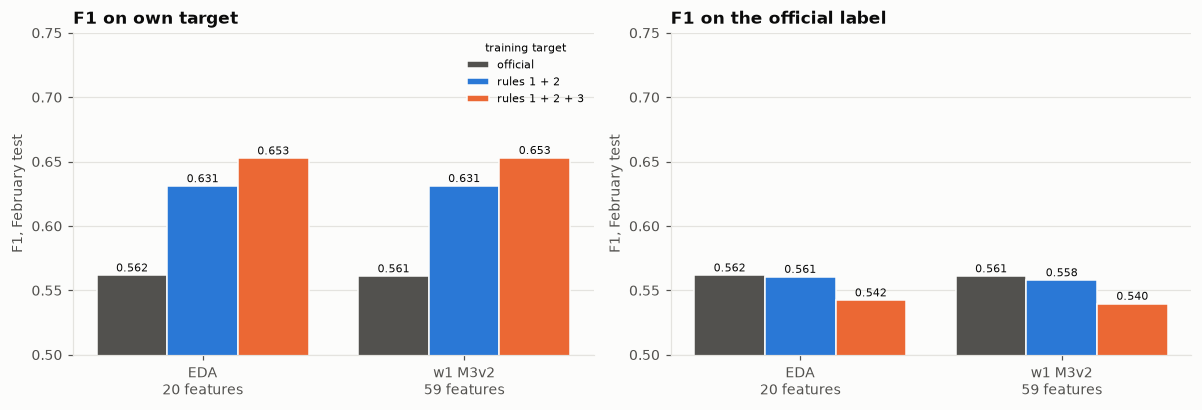

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
colors = {"official": C.COLORS["base"], "rules 1 + 2": C.COLORS["stay"], "rules 1 + 2 + 3": C.COLORS["churn"]}
x, w = np.arange(2), 0.27
for ax, (title, sel) in zip(axes, (("F1 on own target", None), ("F1 on the official label", "official"))):
    for j, target in enumerate(TARGETS):
        vals = [res[(res["model"] == m) & (res["training target"] == target) & (res["threshold by"] == "F1")
                    & (res["evaluated on"] == (sel or target))]["F1"].item() for m in (M20, M59)]
        ax.bar(x + (j - 1) * w, vals, w, color=colors[target], label=target, edgecolor=C.COLORS["surface"])
        for xi, v in zip(x + (j - 1) * w, vals):
            ax.text(xi, v + 0.003, f"{v:.3f}", ha="center", fontsize=7, color=C.COLORS["text"])
    ax.set_xticks(x, ["EDA\n20 features", "w1 M3v2\n59 features"]); ax.set_ylim(0.5, 0.75)
    ax.set_ylabel("F1, February test"); ax.set_title(title, loc="left")
axes[0].legend(frameon=False, fontsize=7, title="training target", title_fontsize=7)
fig.tight_layout(); C.save_fig(fig, "14_february_only_split"); plt.show()

## 7. Conclusion

**Without March, the relabelled targets are easier to predict but cost a little on the official February label,
and the two models tie.** February `test` (148,939 customers), threshold = max F1 on `tune`:

| model | training target | churn rate (own target) | AP (own) | F1 (own) | F1 on official label | d F1 on official (95 % CI) |
|---|---|---|---|---|---|---|
| EDA, 20 features | official | 6.4 % | 0.601 | 0.562 | 0.562 | |
| | rules 1 + 2 | 8.2 % | 0.682 | 0.631 | 0.561 | −0.001 (−0.004, +0.002) |
| | rules 1 + 2 + 3 | 8.6 % | 0.713 | 0.653 | 0.542 | −0.019 (−0.023, −0.016) |
| w1 M3v2, 59 features | official | 6.4 % | 0.600 | 0.561 | 0.561 | |
| | rules 1 + 2 | 8.2 % | 0.683 | 0.631 | 0.558 | −0.003 (−0.006, +0.001) |
| | rules 1 + 2 + 3 | 8.6 % | 0.714 | 0.653 | 0.540 | −0.021 (−0.025, −0.018) |

- **The two feature sets are equivalent inside February** (F1 0.562 vs 0.561, AP 0.601 vs 0.600 on the official
  label; 0.653 vs 0.653 with rules 1 + 2 + 3). The 20-feature advantage seen in notebooks 09 and 13 appears only
  when the model is moved to March: the 20 features transfer better, they do not fit February better.
- **Each relabelled target is learned better than the official one** (F1 0.56 → 0.63 → 0.65), and both models
  stay calibrated on every target and every expiry group. Part of this is mechanical and must not be read as a
  better model: the base rate is higher (6.4 % → 8.6 %), and rule 3 adds 1,169 test churners that are fully
  determined by `expiry_month = later` (predicted 1.00, all positive).
- **On the official February label, rules 1 + 2 cost nothing measurable** (−0.001 / −0.003 F1, CIs include 0),
  while rule 3 costs about 0.02 F1: it marks as churn the prepaid customers that the official label calls churn
  only 40 % of the time.
- Nothing in February can say which target is "right": that depends on which definition the model will be judged
  with. Notebook 13 showed that against the `train_v2` definition the relabelled targets win (+0.008 / +0.044 F1
  with 20 features); here, against the `train` definition, rules 1 + 2 are neutral and rule 3 loses.

**Recommendation.**
1. Rules 1 + 2 are safe: neutral on the official February label, better on March. Use them as the default
   training target.
2. Rule 3 is a bet on the `train_v2` definition: +0.044 F1 on March, −0.019 on February. Use it only if the model
   is evaluated with the March label, and keep it marked exploratory.
3. Choose between the 20 and 59 features on transfer, not on a February holdout: inside February they tie.

In [10]:
C.write_decisions("14", "Relabelled target with a February-only split (70 / 15 / 15)", [
    {"finding": "On a February-only split (train 70 / tune 15 / test 15, March never read) the 20 and 59 features tie: F1 0.562 vs 0.561 and AP 0.601 vs 0.600 on the official label, 0.653 vs 0.653 with rules 1 + 2 + 3",
     "decision": "Choose the feature set on transfer to another month (notebooks 09 and 13), not on a February holdout", "kind": "no action"},
    {"finding": "Relabelled targets are learned better on their own label (F1 0.56 -> 0.63 -> 0.65, AP 0.60 -> 0.68 -> 0.71) and stay calibrated, but partly mechanically: higher base rate, and rule 3 positives are fully determined by expiry_month = later",
     "decision": "Never compare targets by their own-label metrics; compare them on a common evaluation label", "kind": "no action"},
    {"finding": "On the official February label rules 1 + 2 cost nothing measurable (d F1 -0.001 / -0.003, CIs include 0); rule 3 costs about 0.02 F1 (-0.019 / -0.021)",
     "decision": "Rules 1 + 2 are the default training target (neutral on train, better on train_v2); rule 3 only when the evaluation label is train_v2, still exploratory", "kind": "open"},
])

,finding,decision,kind
0,On a February-only split (train 70 / tune 15 /...,Choose the feature set on transfer to another ...,no action
1,Relabelled targets are learned better on their...,Never compare targets by their own-label metri...,no action
2,On the official February label rules 1 + 2 cos...,Rules 1 + 2 are the default training target (n...,open
